# ДЗ Теорвер Васильева Анна

 Ноутбук к заданиям 2 и 3 (решения задач 1 в PDF-файле).


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": False})

## 2. Симуляции в Python

### Задание 2.1. Нормальная выборка

5000 значений из $N(40,\ 8^2)$, гистограмма и теоретическая плотность поверх.

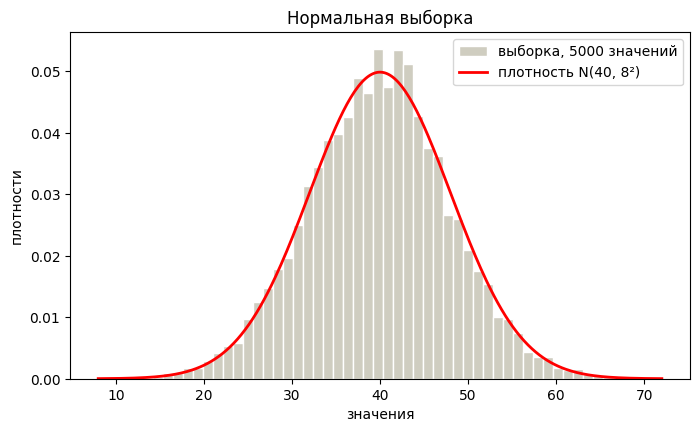

Среднее:  значение из выборки 39.841, задано 40
Ст. откл.: значение из выборки 7.996, задано 8


In [51]:
mu, sigma = 40, 8
sample = rng.normal(mu, sigma, size=5000)
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 300) #запас в 4 сигма для отрисовки графика

plt.hist(sample, bins=50, density=True, color="#cfcdc0", edgecolor="white", label="выборка, 5000 значений")
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", lw=2, label="плотность N(40, 8²)")
plt.xlabel("значения"); plt.ylabel("плотности"); plt.title("Нормальная выборка"); plt.legend()
plt.show()

print(f"Среднее:  значение из выборки {sample.mean():.3f}, задано {mu}")
print(f"Ст. откл.: значение из выборки {sample.std(ddof=1):.3f}, задано {sigma}")

**Вывод.** Гистограмма совпадает с теоретической плотностью, а среднее и стандартное отклонение выборки очень близки к заданным 40 и 8. Небольшое расхождение возникает из-за случайности выборки, при росте выборки оно уменьшится.

### Задание 2.2. Биномиальная выборка

5000 значений $Bin(n=1000,\ p=0{,}04)$. 

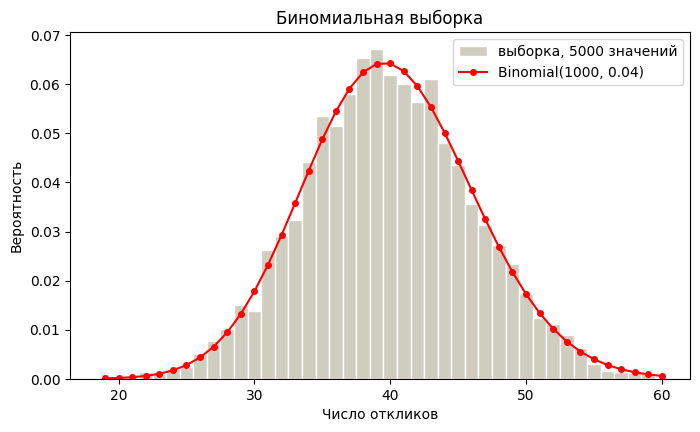

Среднее: значение из выборки 39.900, теория 40.000
Стандартное отклонение: значение из выборки 6.202, теория 6.197


In [52]:
n, p = 1000, 0.04
sample_b = rng.binomial(n, p, size=5000)

k = np.arange(sample_b.min(), sample_b.max() + 1)
plt.hist(sample_b, bins=k - 0.5, density=True, color="#cfcdc0", edgecolor="white", label="выборка, 5000 значений")
plt.plot(k, stats.binom.pmf(k, n, p), "o-", color="red", ms=4, label="Binomial(1000, 0.04)")
plt.xlabel("Число откликов"); plt.ylabel("Вероятность"); plt.title("Биномиальная выборка"); plt.legend()
plt.show()

th_mean, th_std = n*p, (n*p*(1-p))**0.5
print(f"Среднее: значение из выборки {sample_b.mean():.3f}, теория {th_mean:.3f}")
print(f"Стандартное отклонение: значение из выборки {sample_b.std(ddof=1):.3f}, теория {th_std:.3f}")

**Вывод.** Точки теоретической функции вероятности попадают в вершины столбиков, а выборочные среднее и сигма почти совпадают со значениями из формул.

### Задание 2.3. ЦПТ на экспоненциальном распределении

 500 значений в выборке, экспоненциальное распределение, считаем среднее и повторяем 10 000 раз.

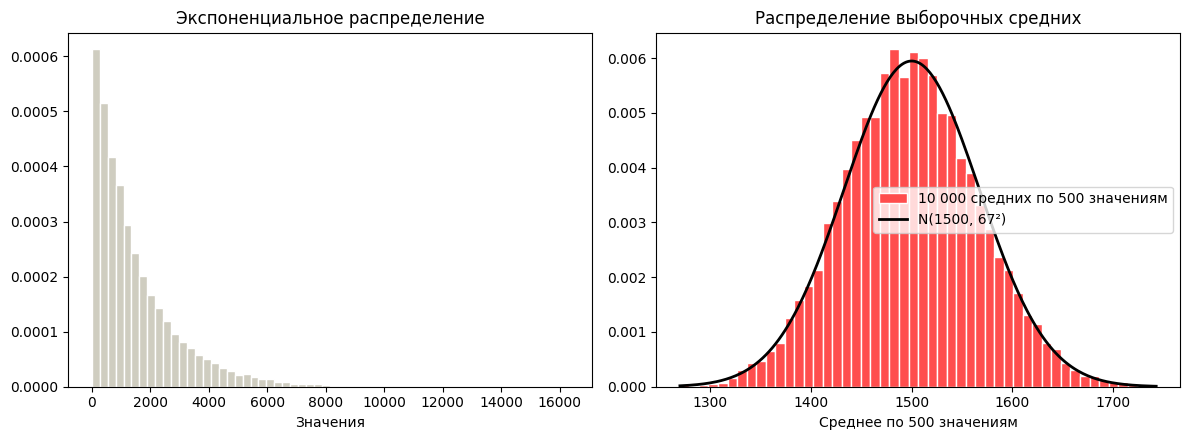

Среднее средних: 1499.0 (теория 1500)
Стандартное отклонение средних: 67.1 (теория σ/(n)^1/2 = 67.1)


In [53]:
scale, n_per_day, n_days = 1500, 500, 10000
means = rng.exponential(scale, size=(n_days, n_per_day)).mean(axis=1)

se = scale / np.sqrt(n_per_day)
xs = np.linspace(means.min(), means.max(), 300)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(rng.exponential(scale, 50000), bins=60, density=True, color="#cfcdc0", edgecolor="white")
ax[0].set_title("Экспоненциальное распределение"); ax[0].set_xlabel("Значения")
ax[1].hist(means, bins=50, density=True, color="#ff4d4d", edgecolor="white", label="10 000 средних по 500 значениям")
ax[1].plot(xs, stats.norm.pdf(xs, scale, se), "k", lw=2, label="N(1500, 67²)")
ax[1].set_title("Распределение выборочных средних"); ax[1].set_xlabel("Среднее по 500 значениям"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Среднее средних: {means.mean():.1f} (теория {scale})")
print(f"Стандартное отклонение средних: {means.std(ddof=1):.1f} (теория σ/(n)^1/2 = {se:.1f})")

**Вывод.** Исходные значения распределены экспоненциально, сильно перекошены вправо и совсем не похожи на колокол. Но гистограмма средних по 500 значениям симметрична и почти совпадает с нормальной кривой $N(1500,\ 67^2)$: центр в истинном $\mu = 1500$, ширина равна $σ/\sqrt n \approx 67$. Это центральная предельная теорема: среднее большого числа независимых одинаково распределённых величин с конечной дисперсией приближённо нормально, каким бы ни было исходное распределение. Колокол получился только из-за усреднения.

## 3. Мини-кейс про кнопку


### Задание 3.1. Посчитать по формуле

In [54]:
n = 5000
p_old, p_new = 155/n, 170/n
se_old = np.sqrt(p_old*(1-p_old)/n)
se_new = np.sqrt(p_new*(1-p_new)/n)
se_diff = np.sqrt(se_old**2 + se_new**2)
diff = p_new - p_old

print(f"Старая: p = {p_old:.2%}, SE = {se_old*100:.3f}")
print(f"Новая:  p = {p_new:.2%}, SE = {se_new*100:.3f}")
print(f"Разница: {diff*100:.2f}, SE разницы = {se_diff*100:.3f} ")
print(f"Разница / SE разницы = {diff/se_diff:.2f}")

Старая: p = 3.10%, SE = 0.245
Новая:  p = 3.40%, SE = 0.256
Разница: 0.30, SE разницы = 0.355 
Разница / SE разницы = 0.85



**Вывод.** Конверсия каждый день немного скачет, даже если ничего не менять. В данном случае такой случайный скачок около 0.36. А разница между кнопками всего 0.3, то есть меньше этого обычного скачка. Значит, такая разница могла получиться случайно. Поэтому пока нельзя сказать, что новая кнопка лучше. Скорее всего, это просто шум. Но и сказать, что она не помогает, тоже нельзя.

### Задание 3.2. Проверить симуляцией

Предположим, что кнопка ни на что не влияет: конверсия в обеих группах одинакова. Много раз смоделируем две группы по 5000 соискателей и посчитаем разницу конверсий.

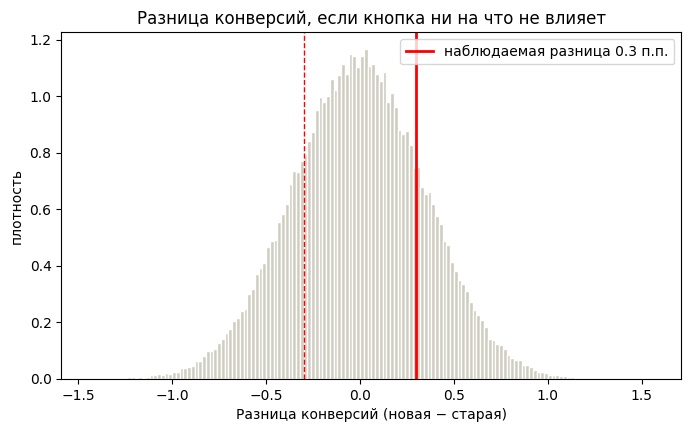

Доля симуляций с разницей >= 0.3: 0.207
Доля симуляций с |разницы| >= 0.3: 0.413
Стандартное отклонение разницы в симуляции: 0.354 (по формуле 0.355)


In [55]:
p0 = (155 + 170) / (2 * n)
n_sim = 100_000
a = rng.binomial(n, p0, size=n_sim)   # отклики в старой группе
b = rng.binomial(n, p0, size=n_sim)   # отклики в новой группе
d = (b - a) / n * 100                 # разница конверсий

obs = (170 - 155) / n * 100           # наблюдаемая разница = 0.3 
share_one = np.mean(d >= obs - 1e-9)
share_two = np.mean(np.abs(d) >= obs - 1e-9)

plt.hist(d, bins=np.arange(d.min(), d.max() + 0.02, 0.02), density=True, color="#cfcdc0", edgecolor="white")
plt.axvline(obs, color="red", lw=2, label=f"наблюдаемая разница {obs:.1f} п.п.")
plt.axvline(-obs, color="red", lw=1, ls="--")
plt.xlabel("Разница конверсий (новая − старая)"); plt.ylabel("плотность")
plt.title("Разница конверсий, если кнопка ни на что не влияет")
plt.legend(); plt.show()

print(f"Доля симуляций с разницей >= 0.3: {share_one:.3f}")
print(f"Доля симуляций с |разницы| >= 0.3: {share_two:.3f}")
print(f"Стандартное отклонение разницы в симуляции: {d.std():.3f} (по формуле {se_diff*100:.3f})")

**Вывод.** Если кнопка ничего не меняет, разница в 0.3 и больше возникает случайно примерно в каждом пятом эксперименте (около 20%, а по модулю в обе стороны около 40%). Это обычное событие, а не редкость. Стандартное отклонение разницы в симуляции (около 0,35). Значит, по этим данным нельзя считать рост конверсии для новой кнопки. Чтобы заметить такой эффект, нужно больше данных.

### Задание 3.3. Выбросы во времени сессий

Время сессий за день, мин: 3, 4, 4, 5, 5, 6, 6, 7, 8, 52.

Три сигмы: среднее = 10.0, сигма = 14.83, границы [-34.5; 54.5] -> выбросы: []
Перцентили: Q1 = 4.25, Q3 = 6.75, границы [0.50; 10.50] -> выбросы: [52]


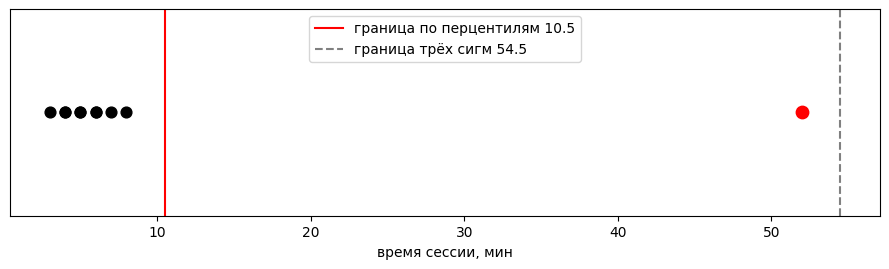

In [56]:
t = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

# правило трёх сигм
m, s = t.mean(), t.std(ddof=1)
lo_3s, hi_3s = m - 3*s, m + 3*s
out_3s = t[(t < lo_3s) | (t > hi_3s)]

# перцентили (правило Тьюки)
q25, q75 = np.percentile(t, [25, 75])
iqr = q75 - q25
lo_p, hi_p = q25 - 1.5*iqr, q75 + 1.5*iqr
out_p = t[(t < lo_p) | (t > hi_p)]

print(f"Три сигмы: среднее = {m:.1f}, сигма = {s:.2f}, границы [{lo_3s:.1f}; {hi_3s:.1f}] -> выбросы: {out_3s}")
print(f"Перцентили: Q1 = {q25}, Q3 = {q75}, границы [{lo_p:.2f}; {hi_p:.2f}] -> выбросы: {out_p}")

plt.figure(figsize=(9, 2.8))
plt.scatter(t, np.zeros_like(t), s=60, color="k", zorder=3)
plt.scatter([52], [0], s=80, color="red", zorder=4)
plt.axvline(hi_p, color="red", label=f"граница по перцентилям {hi_p:.1f}")
plt.axvline(hi_3s, color="gray", ls="--", label=f"граница трёх сигм {hi_3s:.1f}")
plt.yticks([]); plt.xlabel("время сессии, мин"); plt.legend(loc="upper center"); plt.tight_layout(); plt.show()

**Сравнение.**

Очевидно, что 52 минуты на фоне остальных (3–8 минут) — выброс. 

Лучше сработали перцентили. Правило трёх сигм ошиблось, потому что выброс сам участвует в расчёте: он увеличил среднее с 5,3 до 10 и  стандартное отклонение с 1,6 до 14,8, и граница 54,5 находится правее выброса. Перцентили зависят от порядка значений, а не от их величины. Выборка маленькая и сильно перекошена вправо, а правило трёх сигм рассчитано на нормальное распределение.
